# 01 · Exploración de los datos

**Fase CRISP-DM:** *Data Understanding*. Qué significa cada columna, de dónde vienen los datos, cuántos nulos hay y qué rangos y distribuciones tienen. Los gráficos son rápidos y solo para el equipo: aquí se buscan patrones y problemas, no se pule nada.

- **Entrada:** `data/raw/10.000_Empresas_mas_Grandes_del_País.csv` (si no está, se descarga solo).
- **Salida:** ninguna. La lista de problemas del final es la guía de `02_limpieza.ipynb`.

In [1]:
# Permite importar src/ desde la carpeta notebooks/
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src import estilo, utils

estilo.apply_style()

## 1. Origen y contenido

[10.000 Empresas más Grandes del País](https://www.datos.gov.co/Comercio-Industria-y-Turismo/10-000-Empresas-mas-Grandes-del-Pa-s/6cat-2gcs/about_data), de la Superintendencia de Sociedades en Datos Abiertos Colombia (reto *Datos al Ecosistema 2025*, MinTIC). Cada año de corte (2021-2025) trae las 10.000 empresas con mayores ingresos operacionales.

In [2]:
raw = utils.load_raw()
print(raw.shape)
raw.head()

(50000, 14)


,NIT,RAZÓN SOCIAL,SUPERVISOR,REGIÓN,DEPARTAMENTO DOMICILIO,CIUDAD DOMICILIO,CIIU,MACROSECTOR,INGRESOS OPERACIONALES,GANANCIA (PÉRDIDA),TOTAL ACTIVOS,TOTAL PASIVOS,TOTAL PATRIMONIO,Año de Corte
0,899999068,ECOPETROL S.A.,SUPERFINANCIERA,BOGOTÁ - CUNDINAMARCA,BOGOTA D.C.,"BOGOTA, D.C.",610,MINERO,$ 100.59,$ 9.03,$ 198.11,$ 114.35,$ 83.76,2025
1,830095213,ORGANIZACIÓN TERPEL S.A.,SUPERFINANCIERA,BOGOTÁ - CUNDINAMARCA,BOGOTA D.C.,"BOGOTA, D.C.",4661,COMERCIO,$ 26.40,$ 0.63,$ 8.11,$ 4.70,$ 3.41,2025
2,900112515,REFINERIA DE CARTAGENA S.A.,SUPERSERVICIOS,REGIÓN CARIBE,BOLIVAR,CARTAGENA,1921,MANUFACTURA,$ 22.40,-$ 0.82,$ 34.95,$ 11.57,$ 23.38,2025
3,900276962,D1 S.A.S.,SUPERSOCIEDADES,BOGOTÁ - CUNDINAMARCA,BOGOTA D.C.,"BOGOTA, D.C.",4711,COMERCIO,$ 21.61,$ 0.42,$ 6.94,$ 6.72,$ 0.21,2025
4,890904996,EMPRESAS PÚBLICAS DE MEDELLÍN E.S.P.,SUPERFINANCIERA,ANTIOQUIA,ANTIOQUIA,MEDELLÍN,3513,SERVICIOS,$ 20.29,$ 4.88,$ 71.08,$ 36.11,$ 34.97,2025


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   NIT                     50000 non-null  int64
 1   RAZÓN SOCIAL            50000 non-null  str  
 2   SUPERVISOR              50000 non-null  str  
 3   REGIÓN                  50000 non-null  str  
 4   DEPARTAMENTO DOMICILIO  50000 non-null  str  
 5   CIUDAD DOMICILIO        50000 non-null  str  
 6   CIIU                    50000 non-null  int64
 7   MACROSECTOR             50000 non-null  str  
 8   INGRESOS OPERACIONALES  50000 non-null  str  
 9   GANANCIA (PÉRDIDA)      50000 non-null  str  
 10  TOTAL ACTIVOS           50000 non-null  str  
 11  TOTAL PASIVOS           50000 non-null  str  
 12  TOTAL PATRIMONIO        50000 non-null  str  
 13  Año de Corte            50000 non-null  int64
dtypes: int64(3), str(11)
memory usage: 10.8 MB


**Diccionario de datos.** Las cifras están en billones de pesos colombianos (COP).

| Columna original | En el proyecto | Qué es |
|---|---|---|
| `NIT` | `nit` | Número de identificación tributaria de la empresa |
| `RAZÓN SOCIAL` | `company_name` | Nombre legal de la empresa |
| `SUPERVISOR` | `supervisor` | Superintendencia que vigila a la empresa |
| `REGIÓN` | `region` | Región del domicilio |
| `DEPARTAMENTO DOMICILIO` | `department` | Departamento del domicilio |
| `CIUDAD DOMICILIO` | `city` | Municipio del domicilio |
| `CIIU` | `ciiu` | Código de actividad económica (4 dígitos) |
| `MACROSECTOR` | `macrosector` | Agrupación de la actividad: comercio, servicios, manufactura, construcción, agropecuario o minero |
| `INGRESOS OPERACIONALES` | `operating_revenue` | Ingresos de la actividad principal |
| `GANANCIA (PÉRDIDA)` | `net_income` | Resultado neto del año (negativo = pérdida) |
| `TOTAL ACTIVOS` | `total_assets` | Lo que la empresa posee |
| `TOTAL PASIVOS` | `total_liabilities` | Lo que la empresa debe |
| `TOTAL PATRIMONIO` | `total_equity` | Activos menos pasivos (negativo = debe más de lo que tiene) |
| `Año de Corte` | `year` | Año del ranking |

## 2. Formato mínimo para explorar

Columnas en snake_case y en inglés, y cifras de texto (`$ 100.59`) a número. Es solo para poder explorar: la limpieza completa está en `02_limpieza.ipynb` y aquí no se guarda nada.

In [4]:
df = utils.rename_columns(raw)
df[utils.FINANCIAL_COLS] = df[utils.FINANCIAL_COLS].apply(utils.parse_amounts)

print("Valores que no se pudieron convertir:", df[utils.FINANCIAL_COLS].isna().sum().sum())
df.head()

Valores que no se pudieron convertir: 0


,nit,company_name,supervisor,region,department,city,ciiu,macrosector,operating_revenue,net_income,total_assets,total_liabilities,total_equity,year
0,899999068,ECOPETROL S.A.,SUPERFINANCIERA,BOGOTÁ - CUNDINAMARCA,BOGOTA D.C.,"BOGOTA, D.C.",610,MINERO,100.59,9.03,198.11,114.35,83.76,2025
1,830095213,ORGANIZACIÓN TERPEL S.A.,SUPERFINANCIERA,BOGOTÁ - CUNDINAMARCA,BOGOTA D.C.,"BOGOTA, D.C.",4661,COMERCIO,26.40,0.63,8.11,4.70,3.41,2025
2,900112515,REFINERIA DE CARTAGENA S.A.,SUPERSERVICIOS,REGIÓN CARIBE,BOLIVAR,CARTAGENA,1921,MANUFACTURA,22.40,-0.82,34.95,11.57,23.38,2025
3,900276962,D1 S.A.S.,SUPERSOCIEDADES,BOGOTÁ - CUNDINAMARCA,BOGOTA D.C.,"BOGOTA, D.C.",4711,COMERCIO,21.61,0.42,6.94,6.72,0.21,2025
4,890904996,EMPRESAS PÚBLICAS DE MEDELLÍN E.S.P.,SUPERFINANCIERA,ANTIOQUIA,ANTIOQUIA,MEDELLÍN,3513,SERVICIOS,20.29,4.88,71.08,36.11,34.97,2025


## 3. Calidad de los datos

### Nulos y duplicados

In [5]:
print("Valores nulos:", df.isna().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())
# Cada empresa debería tener un único registro por año
print("Filas con NIT repetido en el mismo año:", df.duplicated(subset=["nit", "year"]).sum())

Valores nulos: 0
Filas duplicadas: 0


Filas con NIT repetido en el mismo año: 0


### Supervisores y regiones por año

In [6]:
pd.crosstab(df["supervisor"], df["year"])

year,2021,2022,2023,2024,2025
supervisor,,,,,
SUPERFINANCIERA,58,58,55,50,47
SUPERSALUD,921,787,710,467,0
SUPERSERVICIOS,3,2,205,210,244
SUPERSOCIEDADES,8818,8960,8536,8520,8916
SUPERTRANSPORTE,1,8,310,548,583
SUPERVIGILANCIA,199,185,184,205,210


Supersalud desaparece del ranking en 2025.

In [7]:
pd.crosstab(df["region"], df["year"])

year,2021,2022,2023,2024,2025
region,,,,,
ANTIOQUIA,1922,1899,1859,1851,1876
BOGOTÁ - CUNDINAMARCA,4590,4700,4645,4702,4807
CENTRO - ORIENTE,584,578,622,595,566
CENTRO - SUR,0,0,0,0,193
COSTA ATLÁNTICA,1098,1063,1092,979,0
COSTA PACÍFICA,1099,1088,1059,1032,1034
EJE CAFETERO,355,352,348,364,372
LLANOS,0,0,0,0,165
OTROS,352,320,375,477,0


En 2025 cambian los nombres de las regiones: desaparecen `COSTA ATLÁNTICA` y `OTROS`, y aparecen `REGIÓN CARIBE`, `CENTRO - SUR` y `LLANOS`.

### Ciudades y departamentos escritos de varias formas

Se agrupan los nombres por sus 3 primeras letras para ver variantes del mismo municipio.

In [8]:
print("Ciudades distintas:", df["city"].nunique())
for prefix, names in utils.explore_prefix_variants(df["city"]).items():
    print(f"Prefijo '{prefix}': {names}")

Ciudades distintas: 456
Prefijo 'ACA': ['ACACÍAS', 'ACACIAS']
Prefijo 'AGU': ['AGUAZUL', 'AGUACHICA']
Prefijo 'ALB': ['ALBANIA', 'ALBAN']
Prefijo 'AMA': ['AMAGÁ', 'AMAGA']
Prefijo 'AND': ['ANDALUCÍA', 'ANDES']
Prefijo 'ANS': ['ANSERMA', 'ANSERMANUEVO']
Prefijo 'APA': ['APARTADÓ', 'APARTADO']
Prefijo 'ARA': ['ARAUCA', 'ARAUQUITA', 'ARATOCA']
Prefijo 'ARM': ['ARMENIA', 'ARMERO']
Prefijo 'BAR': ['BARRANQUILLA', 'BARBOSA', 'BARRANCABERMEJA', 'BARANOA', 'BARRANCAS']
Prefijo 'BEL': ['BELLO', 'BELÉN', 'BELEN']
Prefijo 'BOJ': ['BOJACÁ', 'BOJACA']
Prefijo 'BOL': ['BOLÍVAR', 'BOLIVAR']
Prefijo 'BUC': ['BUCARAMANGA', 'BUCARASICA']
Prefijo 'BUE': ['BUENAVENTURA', 'BUENAVISTA', 'BUESACO']
Prefijo 'BUG': ['BUGA', 'BUGALAGRANDE']
Prefijo 'CAJ': ['CAJICÁ', 'CAJICA']
Prefijo 'CAL': ['CALI', 'CALOTO', 'CALDAS', 'CALIMA', 'CALARCÁ', 'CALAMAR', 'CALARCA']
Prefijo 'CAM': ['CAMPOALEGRE', 'CAMPO DE LA CRUZ', 'CAMPO ALEGRE']
Prefijo 'CAR': ['CARTAGENA', 'CARMEN DE VIBORAL', 'CARTAGO', 'CAREPA']
Prefijo 'CER':

In [9]:
print("Departamentos distintos:", df["department"].nunique())
for prefix, names in utils.explore_prefix_variants(df["department"], min_items=1).items():
    print(f"Prefijo '{prefix}': {names}")

Departamentos distintos: 39
Prefijo 'AMA': ['AMAZONAS']
Prefijo 'ANT': ['ANTIOQUIA']
Prefijo 'ARA': ['ARAUCA']
Prefijo 'ARM': ['ARMENIA']
Prefijo 'ATL': ['ATLANTICO']
Prefijo 'BOG': ['BOGOTA D.C.']
Prefijo 'BOL': ['BOLIVAR']
Prefijo 'BOY': ['BOYACA']
Prefijo 'CAL': ['CALDAS']
Prefijo 'CAQ': ['CAQUETA']
Prefijo 'CAS': ['CASANARE']
Prefijo 'CAU': ['CAUCA']
Prefijo 'CES': ['CESAR']
Prefijo 'CHO': ['CHOCO']
Prefijo 'COR': ['CORDOBA']
Prefijo 'CUN': ['CUNDINAMARCA']
Prefijo 'GUA': ['GUAVIARE', 'GUAJIRA', 'GUAINIA']
Prefijo 'HUI': ['HUILA']
Prefijo 'LA ': ['LA GUAJIRA']
Prefijo 'MAG': ['MAGDALENA']
Prefijo 'MET': ['META']
Prefijo 'MON': ['MONTERIA']
Prefijo 'NAR': ['NARINO', 'NARIÑO']
Prefijo 'NOR': ['NORTE DE SANTANDER']
Prefijo 'PUT': ['PUTUMAYO']
Prefijo 'QUI': ['QUINDIO']
Prefijo 'RIS': ['RISARALDA']
Prefijo 'SAN': ['SANTANDER', 'SAN ANDRES Y PROVIDENCIA']
Prefijo 'SUC': ['SUCRE']
Prefijo 'TOL': ['TOLIMA']
Prefijo 'VAL': ['VALLE DEL CAUCA', 'VALLE', 'VALLEDUPAR']
Prefijo 'VAU': ['VAUPES'

Además de tildes y sufijos (`MAICAO GUAJIRA`, `NARIÑO`/`NARINO`), hay capitales escritas en la columna de departamento (`ARMENIA`, `MONTERIA`, `VALLEDUPAR`) y departamentos con dos nombres (`VALLE`/`VALLE DEL CAUCA`).

### Razón social por NIT

In [10]:
names_per_nit = df.groupby("nit")["company_name"].nunique()
nits_with_several_names = names_per_nit[names_per_nit > 1].index
print("NITs con más de una razón social:", len(nits_with_several_names))

# Ejemplos: casi siempre es el mismo nombre con otro tipo de sociedad o espacios de más
(
    df[df["nit"].isin(nits_with_several_names)][["nit", "company_name", "year"]]
    .drop_duplicates()
    .sort_values(["nit", "year"])
    .head(20)
)

NITs con más de una razón social: 3707


,nit,company_name,year
43234,800000118,EMPRESA SOCIAL DEL ESTADO HOSPITAL DEPARTAMEN...,2021
37696,800000118,EMPRESA SOCIAL DEL ESTADO HOSPITAL DEPARTAMEN...,2022
20907,800000118,EMPRESA SOCIAL DEL ESTADO HOSPITAL DEPARTAMENT...,2023
47802,800000457,ACOMEDIOS PUBLICIDAD Y MERCADEO S.A.S.,2021
24963,800000457,ACOMEDIOS PUBLICIDAD Y MERCADEO S.A.S.,2023
15842,800000457,ACOMEDIOS PUBLICIDAD Y MERCADEO S.A.S.,2024
4296,800000457,ACOMEDIOS PUBLICIDAD Y MERCADEO LIMITADA.,2025
40409,800001845,SERPET JR & COMPAÑIA S.A.S.,2021
23677,800001845,SERPET JR & COMPAÑIA S.A.S.,2023
14621,800001845,SERPET JR & COMPAÑIA S.A.S.,2024


### Activos totales en cero

In [11]:
zero_assets = df["total_assets"] == 0
print("Registros con activos en 0:", zero_assets.sum())

# ¿Dato faltante o redondeo? Se revisan los activos de esas mismas empresas en los otros años
same_companies = df["nit"].isin(df.loc[zero_assets, "nit"]) & ~zero_assets
print("Mediana de sus activos en otros años:", df.loc[same_companies, "total_assets"].median())

Registros con activos en 0: 1429
Mediana de sus activos en otros años: 0.01


En otros años esas empresas también tienen activos de casi 0: es el redondeo a 0.01 billones, no un dato faltante.

## 4. Rangos y distribuciones

### Variables financieras

In [12]:
summary = df[utils.FINANCIAL_COLS].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).T
summary["skewness"] = df[utils.FINANCIAL_COLS].skew()
summary["kurtosis"] = df[utils.FINANCIAL_COLS].kurt()
summary.round(2)

,count,mean,std,min,10%,25%,50%,75%,90%,max,skewness,kurtosis
operating_revenue,50000.0,0.17,1.37,0.01,0.02,0.03,0.05,0.10,0.26,144.82,67.97,6017.91
net_income,50000.0,0.01,0.24,-3.21,0.00,0.00,0.00,0.01,0.02,33.41,81.73,9468.25
total_assets,50000.0,0.23,2.42,0.00,0.01,0.02,0.04,0.09,0.29,216.85,62.55,4965.54
total_liabilities,50000.0,0.12,1.42,0.00,0.00,0.01,0.02,0.05,0.15,130.54,68.71,5595.93
total_equity,50000.0,0.11,1.12,-3.69,0.00,0.01,0.01,0.04,0.13,91.03,46.59,3054.89


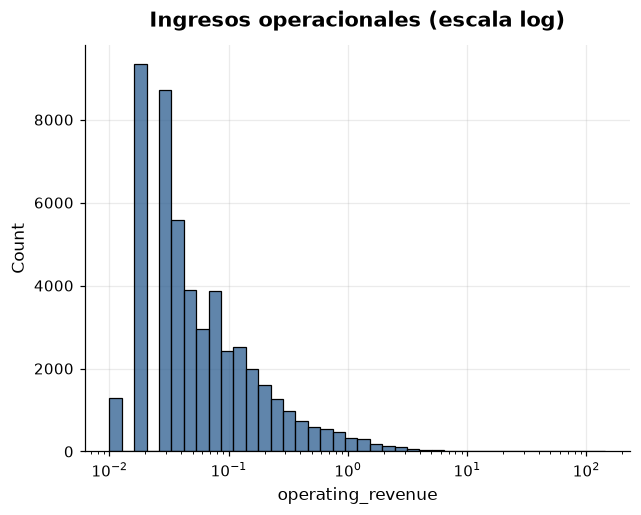

In [13]:
sns.histplot(df["operating_revenue"], bins=40, log_scale=True, color=estilo.MAIN)
plt.title("Ingresos operacionales (escala log)")
plt.show()

In [14]:
# Las cifras vienen redondeadas a 0.01 billones: muchas empresas tienen exactamente el mismo valor
print("Valores distintos de ingresos:", df["operating_revenue"].nunique())
print(f"Registros con ingresos ≤ 0.05 billones: {(df['operating_revenue'] <= 0.05).mean():.0%}")
df["operating_revenue"].value_counts().head(8)

Valores distintos de ingresos: 503
Registros con ingresos ≤ 0.05 billones: 58%


operating_revenue
0.02    9337
0.03    8724
0.04    5571
0.05    3883
0.06    2954
0.07    2162
0.08    1700
0.09    1317
Name: count, dtype: int64

In [15]:
# Spearman, porque es robusta a la fuerte asimetría
df[utils.FINANCIAL_COLS].corr(method="spearman").round(2)

,operating_revenue,net_income,total_assets,total_liabilities,total_equity
operating_revenue,1.00,0.37,0.69,0.68,0.54
net_income,0.37,1.00,0.44,0.29,0.53
total_assets,0.69,0.44,1.00,0.86,0.81
total_liabilities,0.68,0.29,0.86,1.00,0.54
total_equity,0.54,0.53,0.81,0.54,1.00


### Variables categóricas

In [16]:
df[utils.CAT_COLS].nunique()

supervisor       6
region          10
department      39
city           456
ciiu           427
macrosector      6
dtype: int64

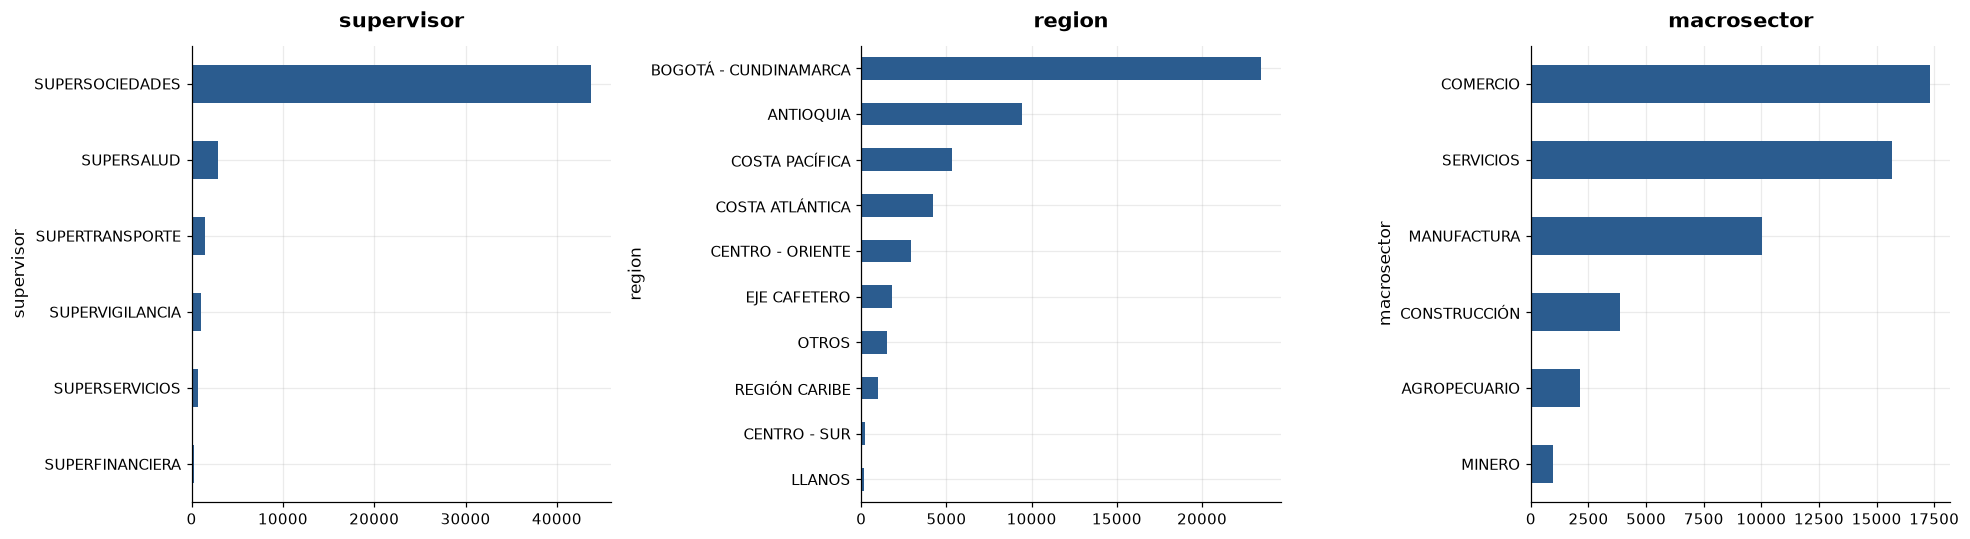

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ["supervisor", "region", "macrosector"]):
    df[col].value_counts().sort_values().plot.barh(ax=ax, color=estilo.MAIN, title=col)
plt.tight_layout()
plt.show()

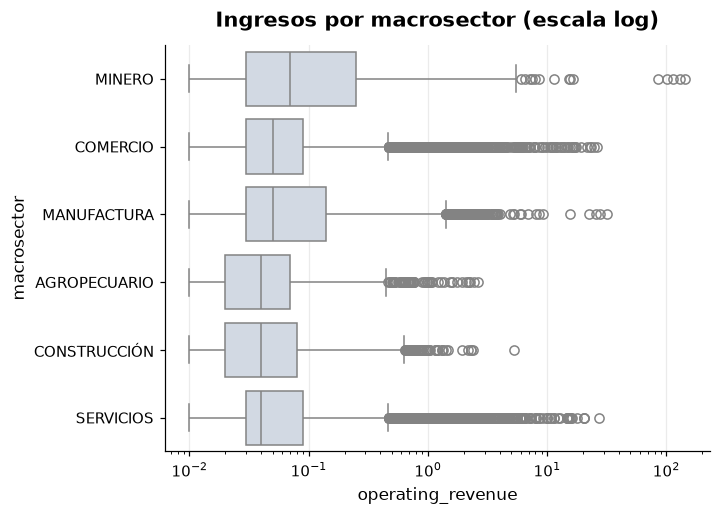

In [18]:
# Ingresos por macrosector, ordenados por mediana
order = df.groupby("macrosector")["operating_revenue"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="operating_revenue", y="macrosector", order=order, log_scale=True, color=estilo.MUTED)
plt.title("Ingresos por macrosector (escala log)")
plt.show()

### Dificultad financiera y permanencia en el ranking

In [19]:
# Dificultad financiera: pérdidas netas o patrimonio negativo
distress = utils.is_distressed(df["net_income"], df["total_equity"])
print(f"Registros en dificultad: {distress.mean():.1%}")
(distress.groupby(df["macrosector"]).mean() * 100).sort_values().round(1)

Registros en dificultad: 5.0%


macrosector
COMERCIO         3.2
AGROPECUARIO     3.8
CONSTRUCCIÓN     4.8
MANUFACTURA      4.9
SERVICIOS        6.6
MINERO          15.3
dtype: float64

In [20]:
(distress.groupby(df["year"]).mean() * 100).round(1)

year
2021    3.7
2022    4.6
2023    5.7
2024    5.8
2025    5.1
dtype: float64

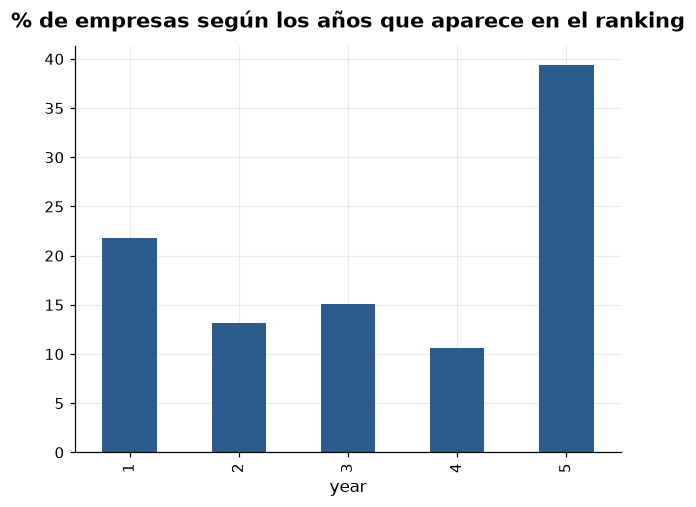

In [21]:
# ¿Cuántos años aparece cada empresa de los 5 posibles?
years_present = df.groupby("nit")["year"].nunique()
(years_present.value_counts(normalize=True).sort_index() * 100).plot.bar(color=estilo.MAIN)
plt.title("% de empresas según los años que aparece en el ranking")
plt.show()

## 5. Hallazgos y qué hacer en la limpieza

| # | Hallazgo | Qué se hace en `02_limpieza` |
|---|---|---|
| 1 | Cifras financieras como texto (`$ 100.59`) y columnas con tildes y espacios | Convertir a número y pasar las columnas a snake_case |
| 2 | El CIIU llega como número y pierde los ceros a la izquierda (`610` en vez de `0610`) | Guardarlo como texto de 4 dígitos |
| 3 | Sin nulos ni duplicados (tampoco NIT repetido en un mismo año) | Nada |
| 4 | Ciudades y departamentos escritos de varias formas, y capitales en la columna de departamento | Normalizar y homologar con los nombres oficiales (DIVIPOLA) |
| 5 | Las regiones cambian de nombre en 2025 | Reconstruir la región desde el departamento, con la clasificación de 2025 |
| 6 | 3.707 NIT con más de una razón social | Conservar la más reciente |
| 7 | 1.429 registros con activos en 0, que son redondeo | Conservarlos |
| 8 | Supersalud desaparece en 2025 y sigue marcos contables especiales | Excluir sus empresas |

Para el modelado: colas muy pesadas (asimetría > 45 y curtosis > 3.000), cifras redondeadas a 0.01 billones, pocas empresas en dificultad y mucha rotación (solo 4 de cada 10 empresas aparecen los 5 años).